In [1]:
!pip install torch torchvision scikit-learn \
    matplotlib seaborn pandas tqdm

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device utilisé :", device)

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

Device utilisé : cuda
GPU : Tesla T4


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Images entraînement :", len(train_dataset))
print("Images test :", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 483kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.42MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.88MB/s]

Images entraînement : 60000
Images test : 10000


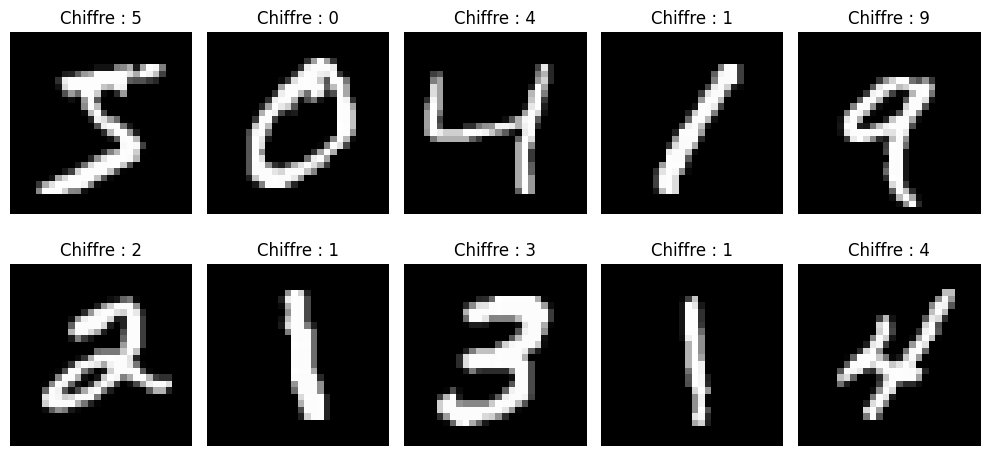

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Chiffre : {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(
            1, 16, kernel_size=3, padding=1
        )
        self.conv2 = nn.Conv2d(
            16, 32, kernel_size=3, padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()

        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        x = torch.flatten(x, 1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

model = CNN().to(device)
print(model)

CNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [6]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 5

In [7]:
train_losses = []
start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    train_losses.append(avg_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {avg_loss:.4f}"
    )

training_time = time.time() - start_time

print(f"Training Time: {training_time:.2f} secondes")

Epoch [1/5], Loss: 0.1951
Epoch [2/5], Loss: 0.0681
Epoch [3/5], Loss: 0.0503
Epoch [4/5], Loss: 0.0411
Epoch [5/5], Loss: 0.0340
Training Time: 74.61 secondes


In [8]:
model.eval()

y_true = []
y_pred = []
test_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred, average="macro")
avg_test_loss = test_loss / len(test_loader)

print("Accuracy :", accuracy)
print("F1-score :", f1)
print("Test Loss :", avg_test_loss)
print("Training Time :", training_time)

Accuracy : 0.9897
F1-score : 0.9896134164265542
Test Loss : 0.029577957350315983
Training Time : 74.60872292518616


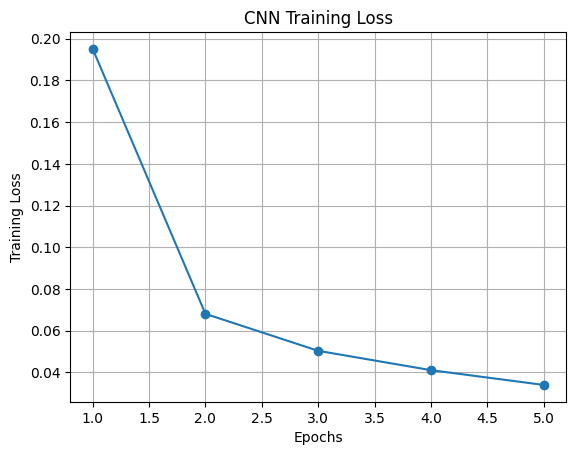

In [9]:
plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("CNN Training Loss")
plt.grid(True)
plt.show()

In [10]:
class MNISTDetection(torch.utils.data.Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, label = self.dataset[idx]

        # Retour à l'échelle [0,1]
        image = image * 0.3081 + 0.1307

        # Convertir 1 canal en 3 canaux
        image = image.repeat(3, 1, 1)

        boxes = torch.tensor(
            [[0., 0., 28., 28.]],
            dtype=torch.float32
        )

        # 0 est réservé à l'arrière-plan
        labels = torch.tensor(
            [label + 1],
            dtype=torch.int64
        )

        target = {
            "boxes": boxes,
            "labels": labels
        }

        return image, target

In [11]:
from torchvision.models.detection import (
    fasterrcnn_mobilenet_v3_large_320_fpn
)

from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor
)

model_frcnn = (
    fasterrcnn_mobilenet_v3_large_320_fpn(
        weights=None,
        weights_backbone=None,
        min_size=128,
        max_size=128
    )
)

in_features = (
    model_frcnn.roi_heads.box_predictor
    .cls_score.in_features
)

model_frcnn.roi_heads.box_predictor = (
    FastRCNNPredictor(in_features, 11)
)

model_frcnn = model_frcnn.to(device)

In [12]:
from torchvision import models

vgg16 = models.vgg16(
    weights=models.VGG16_Weights.DEFAULT
)

for param in vgg16.features.parameters():
    param.requires_grad = False

vgg16.classifier[6] = nn.Linear(4096, 10)

vgg16 = vgg16.to(device)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 160MB/s]


In [13]:
alexnet = models.alexnet(
    weights=models.AlexNet_Weights.DEFAULT
)

for param in alexnet.features.parameters():
    param.requires_grad = False

alexnet.classifier[6] = nn.Linear(4096, 10)

alexnet = alexnet.to(device)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 153MB/s]


In [14]:
results = []

results.append({
    "Model": "CNN",
    "Accuracy": accuracy,
    "F1-score": f1,
    "Loss": avg_test_loss,
    "Training Time (s)": training_time
})

torch.save(model.state_dict(), "cnn_mnist.pth")

pd.DataFrame(results)

,Model,Accuracy,F1-score,Loss,Training Time (s)
0,CNN,0.9897,0.989613,0.029578,74.608723


In [15]:
from torchvision import transforms

transform_pretrained = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_pretrained = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform_pretrained
)

test_pretrained = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform_pretrained
)

train_loader_pretrained = DataLoader(
    train_pretrained,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

test_loader_pretrained = DataLoader(
    test_pretrained,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

images, labels = next(iter(train_loader_pretrained))

print("Shape des images :", images.shape)
print("Shape des labels :", labels.shape)

Shape des images : torch.Size([32, 3, 224, 224])
Shape des labels : torch.Size([32])


In [16]:
def train_and_evaluate(model, model_name, epochs=3):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad,
               model.parameters()),
        lr=0.0001
    )

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for images, labels in train_loader_pretrained:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(
            f"{model_name} - Epoch {epoch+1}/{epochs} "
            f"Loss: {running_loss/len(train_loader_pretrained):.4f}"
        )

    training_time_new = time.time() - start_time

    model.eval()
    y_true = []
    y_pred = []
    test_loss = 0.0

    with torch.no_grad():
        for images, labels in test_loader_pretrained:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            test_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    acc = accuracy_score(y_true, y_pred)
    f1_new = f1_score(
        y_true, y_pred, average="macro"
    )
    avg_loss = test_loss / len(test_loader_pretrained)

    results.append({
        "Model": model_name,
        "Accuracy": acc,
        "F1-score": f1_new,
        "Loss": avg_loss,
        "Training Time (s)": training_time_new
    })

    print(f"\nRésultats {model_name}")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1-score: {f1_new:.4f}")
    print(f"Loss: {avg_loss:.4f}")
    print(f"Training Time: {training_time_new:.2f}s")

    return acc, f1_new

In [17]:
alexnet_acc, alexnet_f1 = train_and_evaluate(
    alexnet,
    "AlexNet",
    epochs=3
)

torch.save(
    alexnet.state_dict(),
    "alexnet_mnist.pth"
)

AlexNet - Epoch 1/3 Loss: 0.1127
AlexNet - Epoch 2/3 Loss: 0.0533
AlexNet - Epoch 3/3 Loss: 0.0427

Résultats AlexNet
Accuracy: 0.9898
F1-score: 0.9898
Loss: 0.0299
Training Time: 320.33s


In [18]:
vgg16_acc, vgg16_f1 = train_and_evaluate(
    vgg16,
    "VGG16",
    epochs=3
)

torch.save(
    vgg16.state_dict(),
    "vgg16_mnist.pth"
)

VGG16 - Epoch 1/3 Loss: 0.0974
VGG16 - Epoch 2/3 Loss: 0.0393
VGG16 - Epoch 3/3 Loss: 0.0300

Résultats VGG16
Accuracy: 0.9902
F1-score: 0.9902
Loss: 0.0407
Training Time: 1174.58s


In [19]:
df_results = pd.DataFrame(results)

print("Comparaison des modèles :")
display(df_results)

df_results.to_csv(
    "comparison_results.csv",
    index=False
)

Comparaison des modèles :


,Model,Accuracy,F1-score,Loss,Training Time (s)
0,CNN,0.9897,0.989613,0.029578,74.608723
1,AlexNet,0.9898,0.989755,0.029896,320.329485
2,VGG16,0.9902,0.990211,0.040683,1174.579612


In [20]:
from torch.utils.data import Subset

train_detection = MNISTDetection(train_dataset)
test_detection = MNISTDetection(test_dataset)

train_subset = Subset(train_detection, range(2000))
test_subset = Subset(test_detection, range(1000))

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader_frcnn = DataLoader(
    train_subset,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_fn
)

test_loader_frcnn = DataLoader(
    test_subset,
    batch_size=4,
    shuffle=False,
    collate_fn=collate_fn
)

print("Training samples:", len(train_subset))
print("Testing samples:", len(test_subset))

Training samples: 2000
Testing samples: 1000


In [21]:
optimizer_frcnn = optim.Adam(
    model_frcnn.parameters(),
    lr=0.0001
)

epochs_frcnn = 2
start_time = time.time()

for epoch in range(epochs_frcnn):

    model_frcnn.train()
    total_loss = 0

    for images, targets in train_loader_frcnn:

        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in t.items()}
            for t in targets
        ]

        optimizer_frcnn.zero_grad()

        loss_dict = model_frcnn(images, targets)
        loss = sum(loss for loss in loss_dict.values())

        loss.backward()
        optimizer_frcnn.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs_frcnn}, "
        f"Loss: {total_loss/len(train_loader_frcnn):.4f}"
    )

training_time_frcnn = time.time() - start_time

print("Training Time:", training_time_frcnn)

torch.save(
    model_frcnn.state_dict(),
    "faster_rcnn_mnist.pth"
)

Epoch 1/2, Loss: 1.7581
Epoch 2/2, Loss: 1.0372
Training Time: 56.440452337265015


In [22]:
model_frcnn.eval()

y_true_frcnn = []
y_pred_frcnn = []

with torch.no_grad():

    for images, targets in test_loader_frcnn:

        images = [img.to(device) for img in images]
        outputs = model_frcnn(images)

        for output, target in zip(outputs, targets):

            true_label = target["labels"][0].item() - 1

            if len(output["labels"]) > 0:
                best_idx = output["scores"].argmax()
                pred_label = (
                    output["labels"][best_idx].item() - 1
                )
            else:
                pred_label = -1

            y_true_frcnn.append(true_label)
            y_pred_frcnn.append(pred_label)

accuracy_frcnn = accuracy_score(
    y_true_frcnn, y_pred_frcnn
)

f1_frcnn = f1_score(
    y_true_frcnn,
    y_pred_frcnn,
    average="macro",
    labels=list(range(10)),
    zero_division=0
)

print("Faster R-CNN Accuracy:", accuracy_frcnn)
print("Faster R-CNN F1-score:", f1_frcnn)
print("Training Time:", training_time_frcnn)

Faster R-CNN Accuracy: 0.759
Faster R-CNN F1-score: 0.7457755881867477
Training Time: 56.440452337265015


In [23]:
results.append({
    "Model": "Faster R-CNN (subset)",
    "Accuracy": accuracy_frcnn,
    "F1-score": f1_frcnn,
    "Loss": float("nan"),
    "Training Time (s)": training_time_frcnn
})

df_results = pd.DataFrame(results)

display(df_results)

,Model,Accuracy,F1-score,Loss,Training Time (s)
0,CNN,0.9897,0.989613,0.029578,74.608723
1,AlexNet,0.9898,0.989755,0.029896,320.329485
2,VGG16,0.9902,0.990211,0.040683,1174.579612
3,Faster R-CNN (subset),0.7590,0.745776,NaN,56.440452


In [24]:
import torch
import torch.nn as nn

class VisionTransformer(nn.Module):

    def __init__(
        self,
        image_size=28,
        patch_size=7,
        num_classes=10,
        embed_dim=64,
        num_heads=4,
        num_layers=4
    ):
        super().__init__()

        self.num_patches = (image_size // patch_size) ** 2

        # Patch Embedding
        self.patch_embed = nn.Conv2d(
            in_channels=1,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # Class Token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # Positional Embedding
        self.pos_embed = nn.Parameter(
            torch.zeros(
                1, self.num_patches + 1, embed_dim
            )
        )

        # Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Classification Head
        self.norm = nn.LayerNorm(embed_dim)
        self.fc = nn.Linear(embed_dim, num_classes)

        nn.init.normal_(self.cls_token, std=0.02)
        nn.init.normal_(self.pos_embed, std=0.02)

    def forward(self, x):

        x = self.patch_embed(x)

        x = x.flatten(2).transpose(1, 2)

        cls_tokens = self.cls_token.expand(
            x.shape[0], -1, -1
        )

        x = torch.cat((cls_tokens, x), dim=1)

        x = x + self.pos_embed

        x = self.transformer(x)

        x = self.norm(x[:, 0])

        x = self.fc(x)

        return x

In [25]:
vit = VisionTransformer().to(device)

print(vit)

total_params = sum(
    p.numel() for p in vit.parameters()
)

print("Nombre de paramètres :", total_params)
print("Device :", device)

VisionTransformer(
  (patch_embed): Conv2d(1, 64, kernel_size=(7, 7), stride=(7, 7))
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (fc): Linear(in_features=64, out_features=10, bias=True)
)
Nombre de paramètres : 205066
Device : cuda


In [26]:
criterion_vit = nn.CrossEntropyLoss()

optimizer_vit = optim.Adam(
    vit.parameters(),
    lr=0.001
)

epochs_vit = 10
vit_train_losses = []

if device.type == "cuda":
    torch.cuda.synchronize()

start_time_vit = time.time()

for epoch in range(epochs_vit):

    vit.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_vit.zero_grad()

        outputs = vit(images)

        loss = criterion_vit(outputs, labels)

        loss.backward()

        optimizer_vit.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    vit_train_losses.append(epoch_loss)

    print(
        f"ViT Epoch [{epoch+1}/{epochs_vit}], "
        f"Loss: {epoch_loss:.4f}"
    )

if device.type == "cuda":
    torch.cuda.synchronize()

training_time_vit = time.time() - start_time_vit

print(
    f"Training Time ViT: {training_time_vit:.2f} s"
)

ViT Epoch [1/10], Loss: 0.6159
ViT Epoch [2/10], Loss: 0.1937
ViT Epoch [3/10], Loss: 0.1395
ViT Epoch [4/10], Loss: 0.1158
ViT Epoch [5/10], Loss: 0.0987
ViT Epoch [6/10], Loss: 0.0911
ViT Epoch [7/10], Loss: 0.0848
ViT Epoch [8/10], Loss: 0.0780
ViT Epoch [9/10], Loss: 0.0723
ViT Epoch [10/10], Loss: 0.0678
Training Time ViT: 224.39 s


In [27]:
vit.eval()

y_true_vit = []
y_pred_vit = []
vit_test_loss = 0.0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = vit(images)

        loss = criterion_vit(outputs, labels)

        vit_test_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        y_true_vit.extend(
            labels.cpu().numpy()
        )

        y_pred_vit.extend(
            predictions.cpu().numpy()
        )

accuracy_vit = accuracy_score(
    y_true_vit, y_pred_vit
)

f1_vit = f1_score(
    y_true_vit,
    y_pred_vit,
    average="macro"
)

avg_test_loss_vit = (
    vit_test_loss / len(test_loader)
)

print("===== ViT RESULTS =====")
print(f"Accuracy: {accuracy_vit:.4f}")
print(f"F1-score: {f1_vit:.4f}")
print(f"Loss: {avg_test_loss_vit:.4f}")
print(f"Training Time: {training_time_vit:.2f} s")

===== ViT RESULTS =====
Accuracy: 0.9812
F1-score: 0.9811
Loss: 0.0630
Training Time: 224.39 s


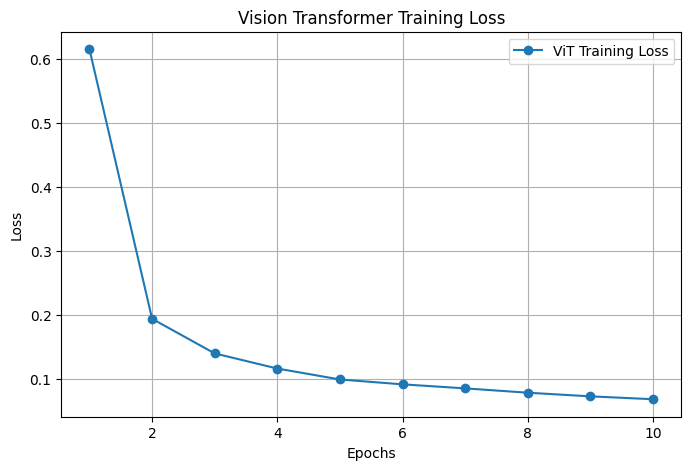

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs_vit + 1),
    vit_train_losses,
    marker="o",
    label="ViT Training Loss"
)

plt.title("Vision Transformer Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
results = [
    r for r in results
    if r["Model"] != "ViT"
]

results.append({
    "Model": "ViT",
    "Accuracy": accuracy_vit,
    "F1-score": f1_vit,
    "Loss": avg_test_loss_vit,
    "Training Time (s)": training_time_vit
})

df_results = pd.DataFrame(results)

display(df_results)

df_results.to_csv(
    "comparison_final.csv",
    index=False
)

torch.save(
    vit.state_dict(),
    "vit_mnist.pth"
)

,Model,Accuracy,F1-score,Loss,Training Time (s)
0,CNN,0.9897,0.989613,0.029578,74.608723
1,AlexNet,0.9898,0.989755,0.029896,320.329485
2,VGG16,0.9902,0.990211,0.040683,1174.579612
3,Faster R-CNN (subset),0.7590,0.745776,NaN,56.440452
4,ViT,0.9812,0.981099,0.062969,224.391034


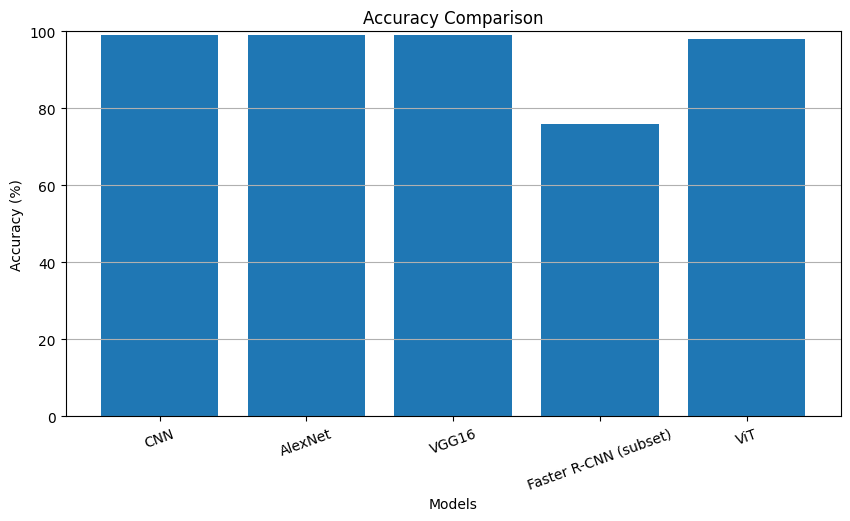

In [30]:
plt.figure(figsize=(10, 5))

plt.bar(
    df_results["Model"],
    df_results["Accuracy"] * 100
)

plt.title("Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("Models")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.show()

In [31]:
from google.colab import files

df_results.to_csv("comparison_final.csv", index=False)
files.download("comparison_final.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>